# Классификация планктона при малом числе примеров

**Евдокимова Мария**

**Датасет:** [WHOI-Plankton](https://huggingface.co/datasets/project-oceania/whoi-plankton), классы с 1–20 изображениями.

**Инструменты:** PyTorch, torchvision, HuggingFace datasets, scikit-learn, matplotlib, seaborn.

**Seed = 67.**

План работы:
1) загрузка и отбор классов,
2) разбиение,
3) предобработка и аугментации,
4) своя CNN (≥3 эксперимента, с/без аугментации),
5) ResNet18 в 4 режимах,
6) сводная таблица и графики,
7) выводы,
8) отчёт PDF и GitHub.


In [ ]:
!pip install -q datasets scikit-learn seaborn matplotlib tabulate markdown weasyprint googledrivedownloader

In [ ]:
import os, random, copy, time, json
from collections import Counter
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T, models
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

RANDOM_SEED = 67
def set_seed(seed=RANDOM_SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

def seed_worker(worker_id):
    s = RANDOM_SEED + worker_id
    np.random.seed(s); random.seed(s)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="ticks", palette="muted")
plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]
)


Device: cuda | torch 2.11.0+cu128


## 1. Загрузка данных и отбор классов (1–20 изображений)

Загружаю все сплиты, объединяю и считаю число картинок по классам. Оставляю только классы с 1–20 изображениями — это и есть постановка с ограниченными данными.


In [ ]:
from datasets import load_dataset, concatenate_datasets, DatasetDict, ClassLabel, Image as HFImage

DATA_PATH = "2006.zip"

# В Colab нет прямого доступа к HuggingFace — скачиваю архив с Drive (только 2006 год)
import googledrivedownloader
googledrivedownloader.download_file_from_google_drive("1JxvGT683EeXCdR8h8Z-QSZvCbjz7zdC3", DATA_PATH)

import zipfile
from datasets import load_dataset

with zipfile.ZipFile(DATA_PATH) as z:
    z.extractall(".")


In [ ]:
raw = load_dataset("imagefolder", data_dir=DATA_PATH[:-4])

# Если HuggingFace доступен:
# raw = load_dataset("project-oceania/whoi-plankton")

print(raw)
ds = concatenate_datasets([raw[s] for s in raw.keys()]) if isinstance(raw, DatasetDict) else raw


Resolving data files:   0%|          | 0/140342 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 140341
    })
})


image column: image | label column: label
Всего классов: 88, изображений: 140341
Выбрано классов (1..20 изображений): 37
Изображений в выбранных классах: 303


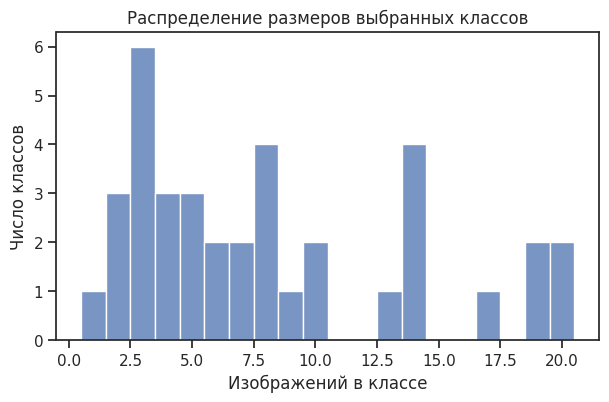

In [ ]:
# автоопределение имён колонок
img_col = [k for k, v in ds.features.items() if isinstance(v, HFImage)][0]
cl_cols = [k for k, v in ds.features.items() if isinstance(v, ClassLabel)]
lab_col = cl_cols[0] if cl_cols else ("label" if "label" in ds.features else
          [k for k in ds.features if k != img_col][0])
print("image column:", img_col, "| label column:", lab_col)

labels_raw = ds[lab_col]  # читаю метки без декодирования картинок
if isinstance(ds.features[lab_col], ClassLabel):
    names = ds.features[lab_col].names
    labels_named = [names[i] for i in labels_raw]
else:
    labels_named = [str(x) for x in labels_raw]

counts = Counter(labels_named)
print(f"Всего классов: {len(counts)}, изображений: {len(labels_named)}")

MIN_COUNT, MAX_COUNT = 1, 20
selected_classes = sorted([c for c, n in counts.items() if MIN_COUNT <= n <= MAX_COUNT])
sel_set = set(selected_classes)
print(f"Выбрано классов (1..20 изображений): {len(selected_classes)}")

indices = [i for i, l in enumerate(labels_named) if l in sel_set]
print("Изображений в выбранных классах:", len(indices))

sel_counts = pd.Series({c: counts[c] for c in selected_classes})
plt.figure(figsize=(7, 4))
sns.histplot(sel_counts.values, bins=range(1, 22), discrete=True, color="#4C72B0")
plt.xlabel("Изображений в классе"); plt.ylabel("Число классов")
plt.title("Распределение размеров выбранных классов")
plt.savefig("figures/class_size_hist.png", dpi=150, bbox_inches="tight"); plt.show()


N = 303 | classes = 37
Размеры: min [121  37] max [1093  943] median [230. 112.]


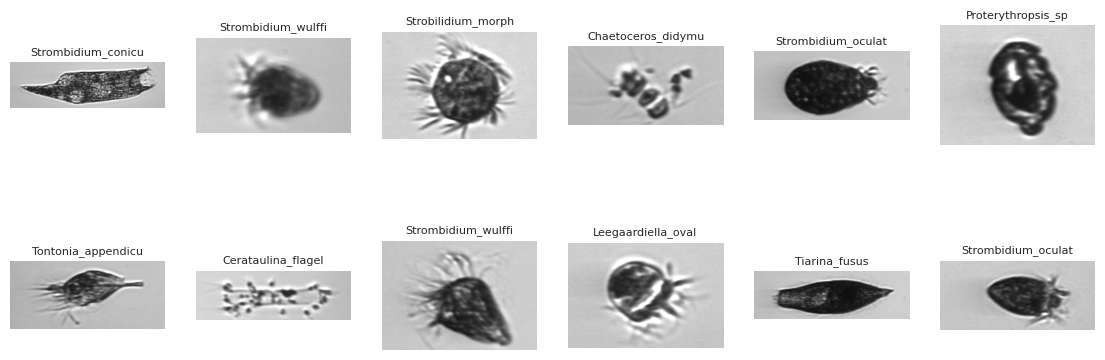

In [ ]:
sub = ds.select(indices)
images = [im.convert("RGB") for im in sub[img_col]]  # grayscale -> 3 канала под ResNet
cls2idx = {c: i for i, c in enumerate(selected_classes)}
y_all = np.array([cls2idx[labels_named[i]] for i in indices])
N_CLASSES = len(selected_classes)
sizes = [im.size for im in images]
print("N =", len(images), "| classes =", N_CLASSES)
print("Размеры: min", np.min(sizes, 0), "max", np.max(sizes, 0), "median", np.median(sizes, 0))

fig, axs = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axs.ravel(), np.random.RandomState(RANDOM_SEED).choice(len(images), 12, replace=False)):
    ax.imshow(images[i]); ax.set_title(selected_classes[y_all[i]][:18], fontsize=8); ax.axis("off")
plt.savefig("figures/samples.png", dpi=150, bbox_inches="tight"); plt.show()


## 2. Разбиение train / val / test

Классы очень малы (1–20 примеров), поэтому разбиваю **внутри каждого класса** (стратифицированно, seed=67):
- n = 1 → только train (такой класс нельзя оценить, он идёт лишь в обучение);
- n = 2 → 1 train + 1 test;
- n ≥ 3 → ~60/20/20, минимум по 1 картинке в val и test.

Val нужен для выбора лучшей эпохи (early stopping), test — только для финальной оценки. Метрики считаю по классам, которые есть в test.


In [ ]:
def per_class_split(y, seed=RANDOM_SEED, val_frac=0.2, test_frac=0.2):
    rng = np.random.RandomState(seed)
    tr, va, te = [], [], []
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0]); n = len(idx)
        if n == 1:
            tr += list(idx); continue
        n_te = max(1, round(test_frac * n))
        n_va = max(1, round(val_frac * n)) if n >= 3 else 0
        te += list(idx[:n_te]); va += list(idx[n_te:n_te + n_va]); tr += list(idx[n_te + n_va:])
    return np.array(tr), np.array(va), np.array(te)

tr_idx, va_idx, te_idx = per_class_split(y_all)
print(f"train={len(tr_idx)}, val={len(va_idx)}, test={len(te_idx)}")
print("Классов в test:", len(np.unique(y_all[te_idx])), "из", N_CLASSES)


train=172, val=64, test=67
Классов в test: 36 из 37


## 3. Предобработка и аугментации

**Предобработка (всегда):** `Resize((224, 224))`, `ToTensor`, `Normalize` со статистикой ImageNet (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) — ResNet18 предобучен на ImageNet.

**Аугментации (только train) и зачем:**

- *Горизонтальный/вертикальный flip, повороты на k·90° и случайный поворот* — планктон снимают в потоке под любым углом, «верха» нет, класс инвариантен к повороту и отражению. Самая безопасная и полезная аугментация.

- *RandomResizedCrop (scale 0.75–1)* — имитирует разный масштаб и положение организма; диапазон мягкий, чтобы не вырезать важные детали.

- *Небольшие яркость/контраст* — разные условия съёмки; цвет почти не используется (картинки почти ч/б), hue/saturation не трогаю.

- *Не применяю* сильные искажения, cutout, mixup: при 1–20 примерах на класс они могут стереть мелкие признаки.


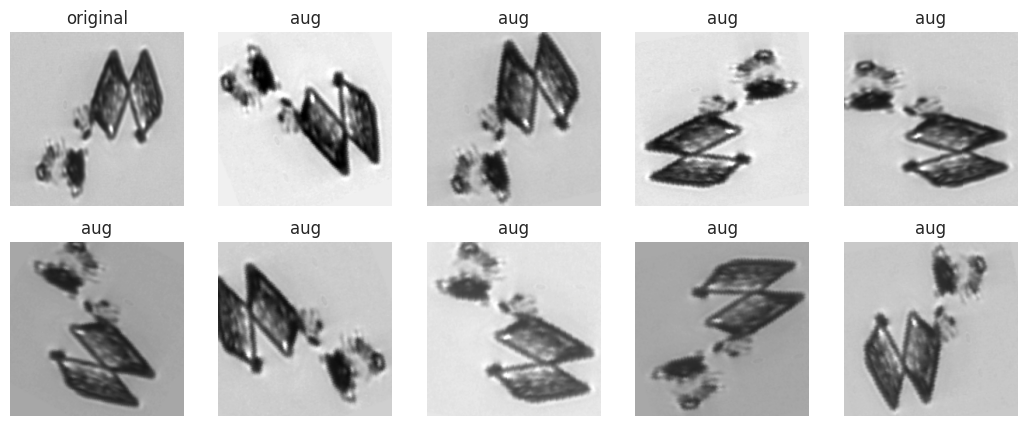

In [ ]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
bg_color = int(np.median([np.array(im)[0, 0, 0] for im in images]))  # цвет фона для заливки при повороте

class RandomRot90:
    def __call__(self, img):
        return img.rotate(90 * random.randint(0, 3), expand=False)

eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
noaug_tf = eval_tf
aug_tf = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    RandomRot90(),
    T.RandomRotation(30, fill=(bg_color, bg_color, bg_color)),
    T.RandomResizedCrop(224, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class PlanktonDataset(Dataset):
    def __init__(self, idx, tf):
        self.idx, self.tf = idx, tf
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        return self.tf(images[j]), int(y_all[j])

def make_loader(idx, tf, shuffle, bs):
    drop = shuffle and (len(idx) % bs == 1)  # BatchNorm плохо переносит батч из 1 элемента
    g = torch.Generator(); g.manual_seed(RANDOM_SEED)
    return DataLoader(PlanktonDataset(idx, tf), batch_size=bs, shuffle=shuffle, drop_last=drop,
                      num_workers=2, worker_init_fn=seed_worker, generator=g)

# визуализация аугментаций
j = tr_idx[0]
fig, axs = plt.subplots(2, 5, figsize=(13, 5))
inv = lambda t: (t * torch.tensor(IMAGENET_STD)[:, None, None] + torch.tensor(IMAGENET_MEAN)[:, None, None]).clamp(0, 1)
axs[0, 0].imshow(inv(eval_tf(images[j])).permute(1, 2, 0)); axs[0, 0].set_title("original")
for ax in axs.ravel()[1:]:
    ax.imshow(inv(aug_tf(images[j])).permute(1, 2, 0)); ax.set_title("aug")
for ax in axs.ravel(): ax.axis("off")
plt.savefig("figures/augmentations.png", dpi=150, bbox_inches="tight"); plt.show()


## 4. Общие функции: метрики, обучение, графики
**Главная метрика — Macro F1.** Лучшую эпоху (сохранение весов и early stopping, patience=10) выбираю по **Macro F1 на val**; balanced accuracy пишу в историю дополнительно. Для замороженных слоёв BatchNorm перевожу в eval, чтобы не портить статистики ImageNet. Precision/Recall/F1 считаю macro по классам, которые есть в val/test. При равном val F1 беру эпоху с меньшим val loss.


In [ ]:
def compute_metrics(y_true, y_pred):
    labs = np.unique(y_true)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, labels=labs, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, labels=labs, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, labels=labs, average="macro", zero_division=0),
    }

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0)

def per_class_f1(y_true, y_pred):
    labs = np.unique(y_true)
    f = f1_score(y_true, y_pred, labels=labs, average=None, zero_division=0)
    return pd.Series(f, index=[selected_classes[l] for l in labs])

def fmt_lr(lr):  # 0.001 -> '1e-3', 5e-5 -> '5e-5'
    return f"{lr:.0e}".replace("e-0", "e-")

@torch.no_grad()
def predict(model, loader, criterion=None):
    model.eval(); ys, ps, tot, n = [], [], 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        if criterion is not None: tot += criterion(out, y).item() * len(y)
        n += len(y); ys.append(y.cpu().numpy()); ps.append(out.argmax(1).cpu().numpy())
    return np.concatenate(ys), np.concatenate(ps), (tot / max(n, 1))

def freeze_bn_if_frozen(model):
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            if all(not p.requires_grad for p in m.parameters()):
                m.eval()

def class_weights():
    cnt = np.bincount(y_all[tr_idx], minlength=N_CLASSES).astype(float)
    w = 1.0 / np.maximum(cnt, 1); w = w / w.mean()
    return torch.tensor(w, dtype=torch.float32, device=device)

def train_model(model, name, train_tf, param_groups, epochs=40, bs=16, optimizer="adam",
                weight_decay=1e-4, use_cw=True, patience=10, label_smoothing=0.0,
                trainable_layers="all", activation="relu", lr_label="", augmentation=True):
    set_seed()
    model = model.to(device)
    tr_loader = make_loader(tr_idx, train_tf, True, bs)
    va_loader = make_loader(va_idx, eval_tf, False, 64)
    te_loader = make_loader(te_idx, eval_tf, False, 64)
    crit = nn.CrossEntropyLoss(weight=class_weights() if use_cw else None, label_smoothing=label_smoothing)
    if optimizer == "adam":
        opt = torch.optim.AdamW(param_groups, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(param_groups, momentum=0.9, weight_decay=weight_decay, nesterov=True)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1", "val_bal_acc"]}
    best_f1, best_vl, best_bal, best_epoch, best_state, bad = -1.0, float("inf"), -1.0, 0, None, 0
    t0 = time.time()
    for ep in range(epochs):
        model.train(); freeze_bn_if_frozen(model)
        tl, tc, n = 0.0, 0, 0
        for x, y in tr_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); out = model(x); loss = crit(out, y)
            loss.backward(); opt.step()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
        sched.step()
        yt, yp, vl = predict(model, va_loader, crit)
        vf1, vbal = macro_f1(yt, yp), balanced_accuracy_score(yt, yp)
        hist["train_loss"].append(tl / n); hist["train_acc"].append(tc / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(accuracy_score(yt, yp))
        hist["val_f1"].append(vf1); hist["val_bal_acc"].append(vbal)
        if vf1 > best_f1 or (vf1 == best_f1 and vl < best_vl):  # критерий: val Macro F1
            best_f1, best_vl, best_bal, best_epoch = vf1, vl, vbal, ep + 1
            best_state, bad = copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
        if bad >= patience: break
    model.load_state_dict(best_state)
    yt, yp, _ = predict(model, te_loader, crit)
    row = {"model": name, "trainable_layers": trainable_layers, "batch_size": bs, "activation": activation,
           "optimizer": "AdamW" if optimizer == "adam" else "SGD+Nesterov", "lr": lr_label,
           "class_weights": use_cw, "augmentation": augmentation,
           "best_epoch": best_epoch, "epochs_run": len(hist["train_loss"]),
           "best_val_f1": best_f1, "best_val_bal_acc": best_bal,
           "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
           "time_s": round(time.time() - t0, 1), **compute_metrics(yt, yp)}
    print(f"[{name}] best_epoch={best_epoch} val_F1={best_f1:.3f} | test acc={row['accuracy']:.3f} "
          f"bal_acc={row['balanced_acc']:.3f} f1_macro={row['f1_macro']:.3f}")
    return row, hist, (yt, yp)

all_results, train_histories, model_preds = [], {}, {}
def register(row, hist, pred):
    all_results.append(row); train_histories[row["model"]] = hist; model_preds[row["model"]] = pred

def plot_history(hist, title, fname=None, best_epoch=None):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    ax[0].plot(hist["train_loss"], label="train", color="#4C72B0")
    ax[0].plot(hist["val_loss"], label="val", color="#DD8452"); ax[0].set_title("Loss")
    ax[1].plot(hist["train_acc"], label="train", color="#4C72B0")
    ax[1].plot(hist["val_acc"], label="val", color="#DD8452"); ax[1].set_title("Accuracy")
    ax[2].plot(hist["val_f1"], label="val Macro F1", color="#55A868")
    ax[2].plot(hist["val_bal_acc"], label="val balanced acc", color="#C44E52", ls="--")
    ax[2].set_title("Val Macro F1 / balanced acc")
    for a in ax:
        if best_epoch:
            a.axvline(best_epoch - 1, color="#8172B3", ls=":", label=f"best epoch = {best_epoch}")
        a.set_xlabel("epoch"); a.legend()
    fig.suptitle(title)
    if fname: fig.savefig(f"figures/{fname}.png", dpi=150, bbox_inches="tight")
    plt.show()


## 5. Собственная CNN: эксперименты

Архитектура: `Input 3×224×224 → Block1 (Conv3×3→BN→Act→MaxPool2, 32) → Block2 (64) → Block3 (128) → Block4 (256) → AdaptiveAvgPool2d(1) → Flatten → FC(256→128) → Activation → Dropout → Output FC(128→K)`.

Activation задаю строкой (`relu | leaky_relu | gelu`) и ставлю и в блоках, и в скрытом слое (флаг `act_in_blocks=False` оставляет в блоках ReLU).

Во всех экспериментах включаю **class weights** (классы несбалансированы: 1–20 картинок), чтобы сравнения были честными.

| Эксп. | channels | activation | dropout | lr | optimizer | wd | bs | аугментация |
|---|---|---|---|---|---|---|---|---|
| CNN-1 | 32-64-128-256 | relu | 0.3 | 1e-3 | AdamW | 1e-4 | 16 | да |
| CNN-2 | 32-64-128-256 | relu | 0.5 | 3e-4 | AdamW | 1e-3 | 16 | да |
| CNN-3 | 64-128-256-512 | relu | 0.5 | 1e-2 | SGD+Nesterov | 5e-4 | 32 | да |
| CNN-1 (no aug) | как CNN-1 | relu | 0.3 | 1e-3 | AdamW | 1e-4 | 16 | нет |
| CNN-2 (no aug) | как CNN-2 | relu | 0.5 | 3e-4 | AdamW | 1e-3 | 16 | нет |
| CNN-4 | как CNN-1 | leaky_relu | 0.3 | 1e-3 | AdamW | 1e-4 | 16 | да |
| CNN-5 | как CNN-1 | gelu | 0.3 | 1e-3 | AdamW | 1e-4 | 16 | да |


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

[CNN-1 (aug)] best_epoch=17 val_F1=0.124 | test acc=0.209 bal_acc=0.197 f1_macro=0.112


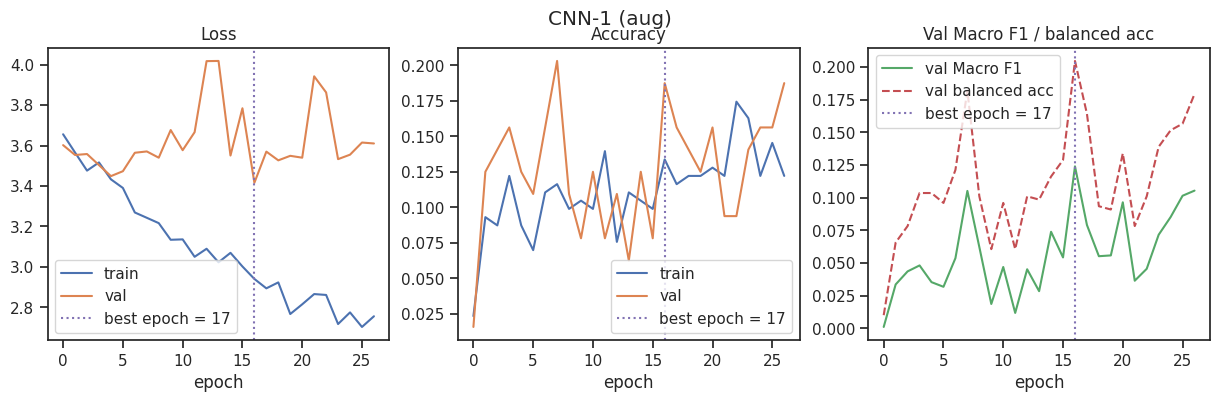

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


[CNN-2 (aug)] best_epoch=4 val_F1=0.064 | test acc=0.194 bal_acc=0.162 f1_macro=0.114


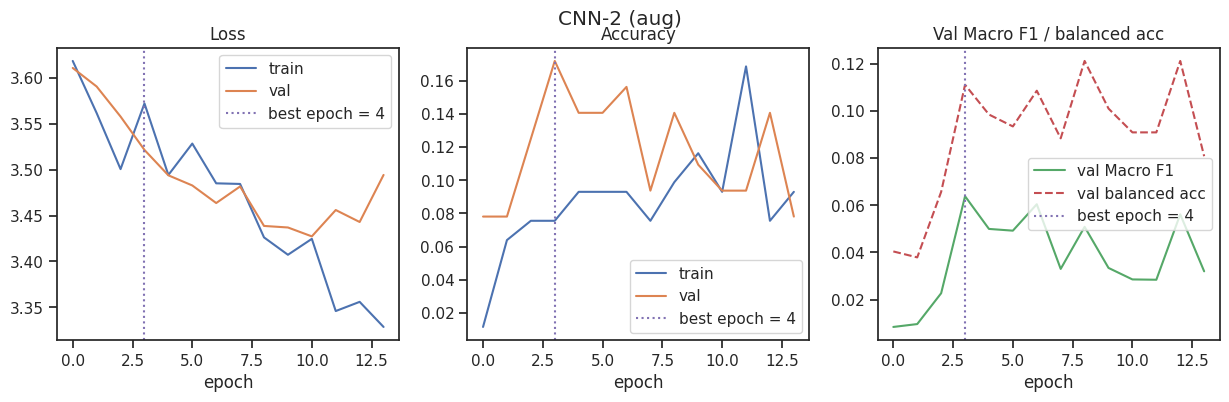

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

[CNN-3 (aug)] best_epoch=33 val_F1=0.133 | test acc=0.164 bal_acc=0.146 f1_macro=0.101


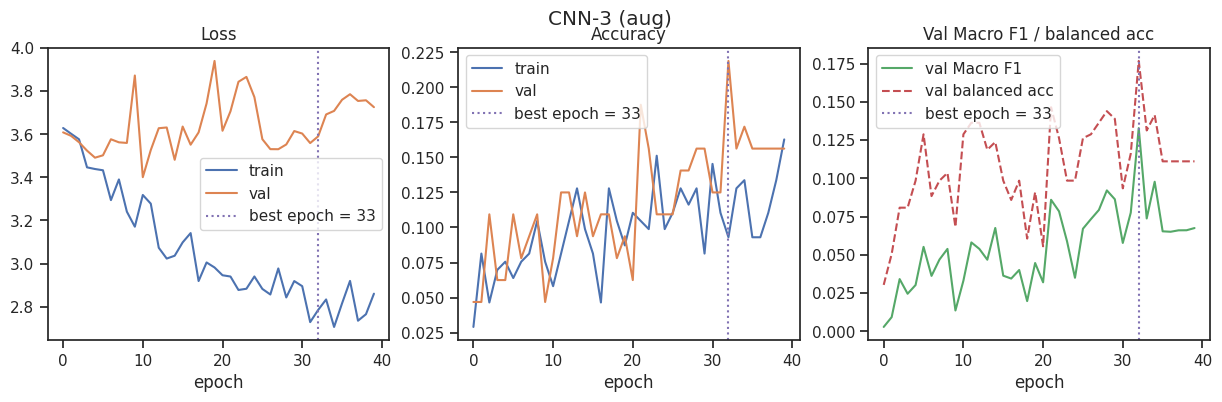

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

[CNN-1 (no aug)] best_epoch=39 val_F1=0.183 | test acc=0.224 bal_acc=0.164 f1_macro=0.118


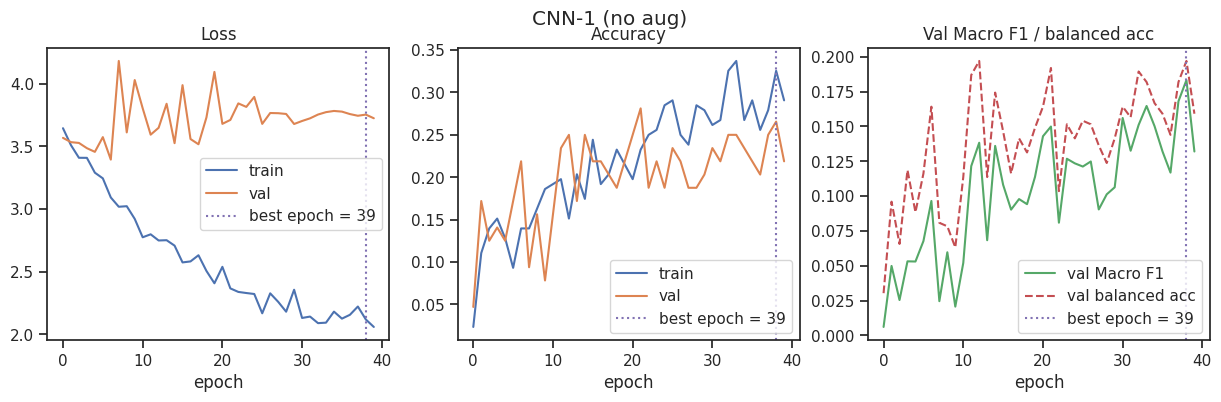

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

[CNN-2 (no aug)] best_epoch=27 val_F1=0.164 | test acc=0.299 bal_acc=0.206 f1_macro=0.162


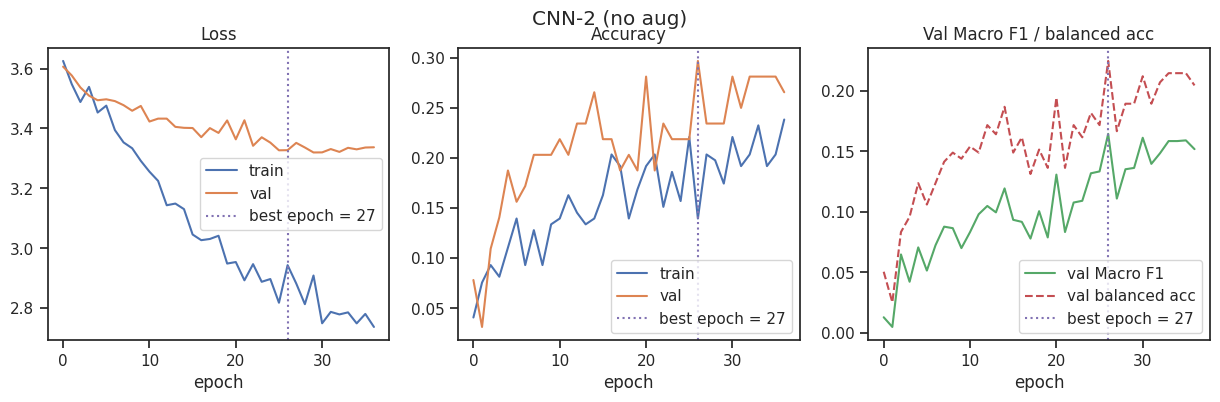

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

[CNN-4 (leaky_relu)] best_epoch=17 val_F1=0.128 | test acc=0.209 bal_acc=0.194 f1_macro=0.131


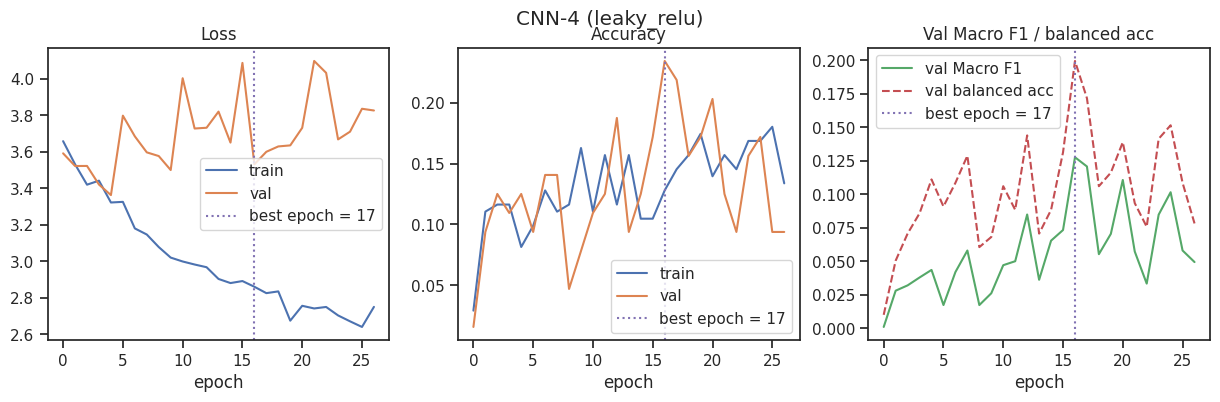

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

[CNN-5 (gelu)] best_epoch=29 val_F1=0.139 | test acc=0.164 bal_acc=0.148 f1_macro=0.111


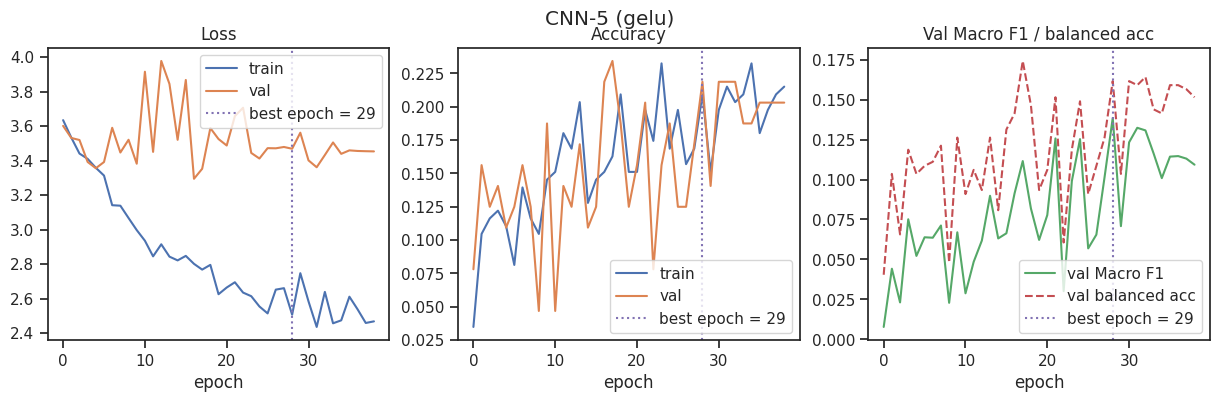

In [ ]:
ACTS = {"relu": lambda: nn.ReLU(inplace=True),
        "leaky_relu": lambda: nn.LeakyReLU(0.1, inplace=True),
        "gelu": lambda: nn.GELU()}

class CustomCNN(nn.Module):
    # Input 3x224x224 -> 4x[Conv3x3 -> BN -> Act -> MaxPool2] -> AdaptiveAvgPool2d(1)
    #   -> FC(hidden) -> Act -> Dropout -> FC(n_classes)
    def __init__(self, n_classes, channels=(32, 64, 128, 256), hidden=128, dropout=0.3,
                 activation="relu", act_in_blocks=True):
        super().__init__()
        block_act = ACTS[activation] if act_in_blocks else ACTS["relu"]
        layers, in_c = [], 3
        for c in channels:
            layers += [nn.Conv2d(in_c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c),
                       block_act(), nn.MaxPool2d(2)]
            in_c = c
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_c, hidden),       # один скрытый FC
            ACTS[activation](),            # Activation
            nn.Dropout(dropout),           # Dropout
            nn.Linear(hidden, n_classes),  # выход
        )
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

# class weights везде включены (cw=True)
CNN_EXPS = [
    dict(name="CNN-1 (aug)",    ch=(32, 64, 128, 256),  act="relu",       do=0.3, lr=1e-3, opt="adam", wd=1e-4, bs=16, aug=True),
    dict(name="CNN-2 (aug)",    ch=(32, 64, 128, 256),  act="relu",       do=0.5, lr=3e-4, opt="adam", wd=1e-3, bs=16, aug=True),
    dict(name="CNN-3 (aug)",    ch=(64, 128, 256, 512), act="relu",       do=0.5, lr=1e-2, opt="sgd",  wd=5e-4, bs=32, aug=True),
    dict(name="CNN-1 (no aug)", ch=(32, 64, 128, 256),  act="relu",       do=0.3, lr=1e-3, opt="adam", wd=1e-4, bs=16, aug=False),
    dict(name="CNN-2 (no aug)", ch=(32, 64, 128, 256),  act="relu",       do=0.5, lr=3e-4, opt="adam", wd=1e-3, bs=16, aug=False),
    # эксперименты с функцией активации
    dict(name="CNN-4 (leaky_relu)", ch=(32, 64, 128, 256), act="leaky_relu", do=0.3, lr=1e-3, opt="adam", wd=1e-4, bs=16, aug=True),
    dict(name="CNN-5 (gelu)",       ch=(32, 64, 128, 256), act="gelu",       do=0.3, lr=1e-3, opt="adam", wd=1e-4, bs=16, aug=True),
]
CNN_EPOCHS = 40

for e in CNN_EXPS:
    set_seed()
    model = CustomCNN(N_CLASSES, e["ch"], dropout=e["do"], activation=e["act"])
    row, hist, pred = train_model(model, e["name"], aug_tf if e["aug"] else noaug_tf,
                                  [{"params": model.parameters(), "lr": e["lr"]}],
                                  epochs=CNN_EPOCHS, bs=e["bs"], optimizer=e["opt"],
                                  weight_decay=e["wd"], use_cw=True,
                                  trainable_layers="all", activation=e["act"],
                                  lr_label=fmt_lr(e["lr"]), augmentation=e["aug"])
    row.update(family="Custom CNN", dropout=e["do"], wd=e["wd"])
    register(row, hist, pred)
    plot_history(hist, e["name"], fname="hist_" + e["name"].replace(" ", "_").replace("(", "").replace(")", ""),
                 best_epoch=row["best_epoch"])


## 6. ResNet18 (pretrained, ImageNet): 4 режима дообучения

| Режим | Trainable layers | lr головы | lr backbone |
|---|---|---|---|
| fc | fc | 1e-3 | – |
| layer4+fc | layer4+fc | 1e-3 | 1e-4 |
| layer3+layer4+fc | layer3+layer4+fc | 1e-3 | 1e-4 |
| full | all | 1e-3 | 5e-5 |

Дискриминативные lr: ранние слои хранят универсальные признаки, их меняю осторожнее, чтобы не переобучиться на малой выборке. Все режимы обучаю с аугментацией, class weights и теми же **40 эпохами с patience=10**, что и свою CNN — бюджеты сопоставимы. Лучшую эпоху выбираю по val Macro F1.


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

[ResNet18 [fc]] best_epoch=14 val_F1=0.432 | test acc=0.403 bal_acc=0.326 f1_macro=0.311


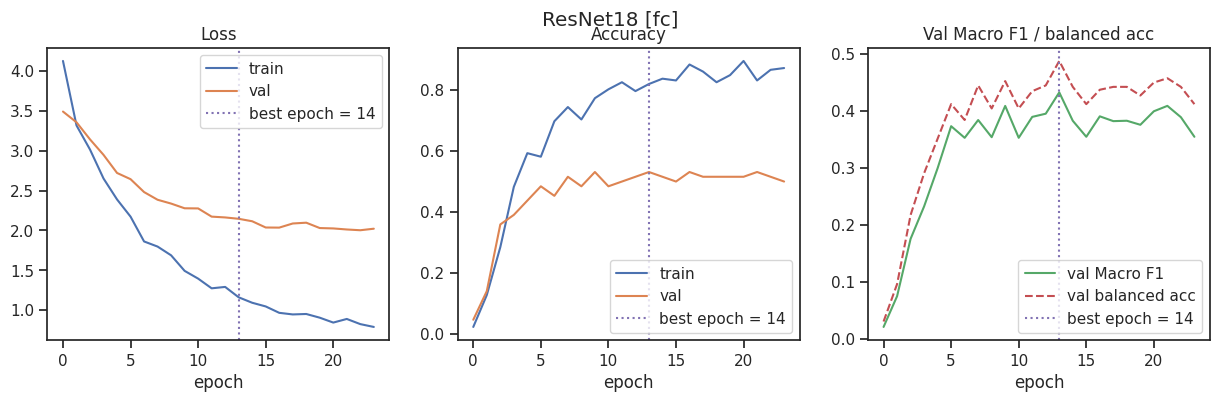

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


[ResNet18 [layer4+fc]] best_epoch=19 val_F1=0.585 | test acc=0.537 bal_acc=0.454 f1_macro=0.434


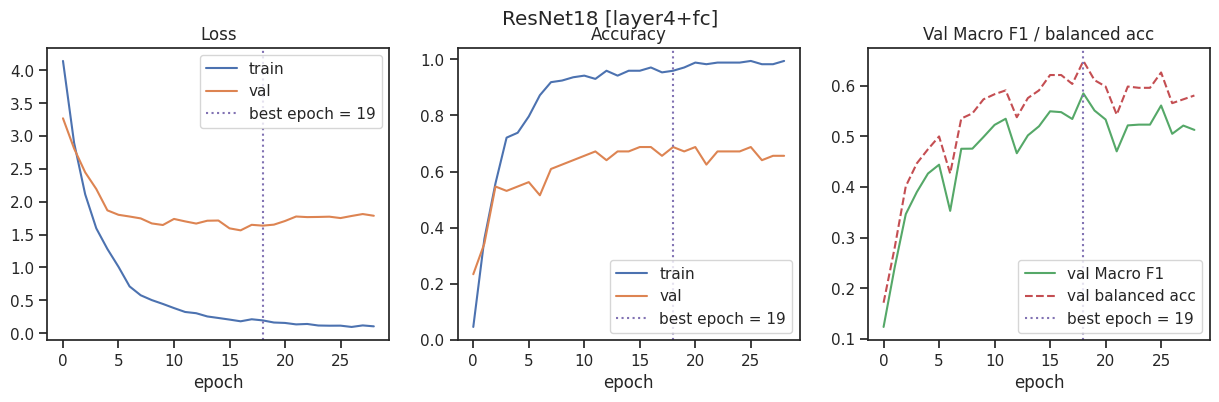

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


[ResNet18 [layer3+layer4+fc]] best_epoch=17 val_F1=0.608 | test acc=0.627 bal_acc=0.567 f1_macro=0.522


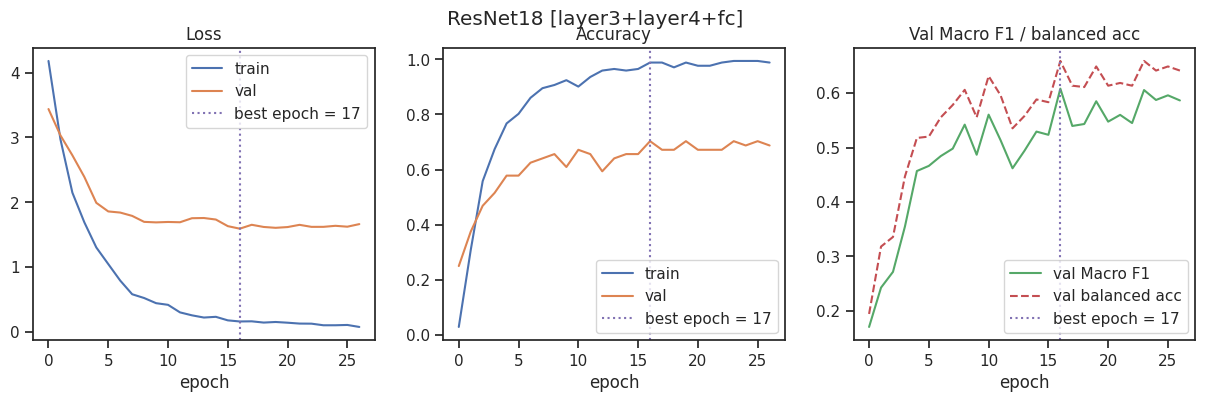

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


[ResNet18 [full]] best_epoch=30 val_F1=0.565 | test acc=0.507 bal_acc=0.398 f1_macro=0.360


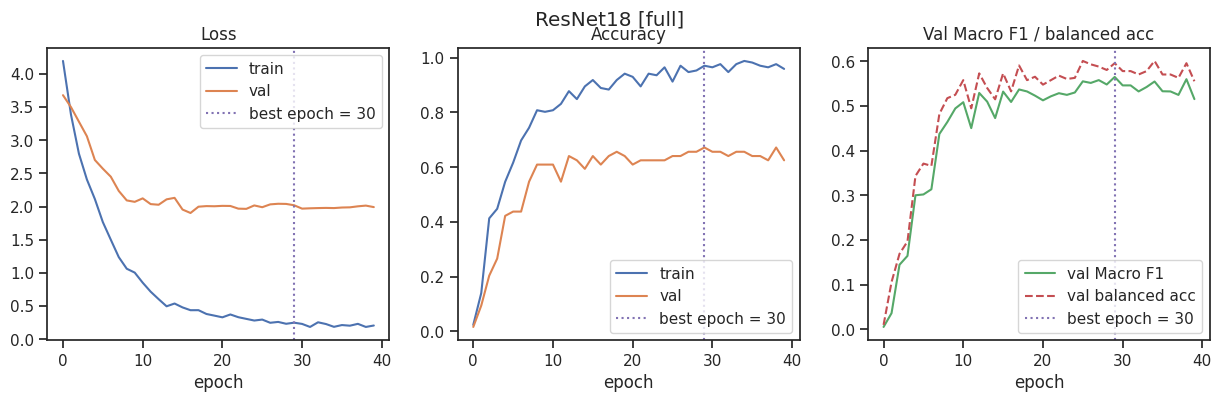

In [ ]:
def build_resnet18(mode, n_classes):
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    cfg = {"fc": ["fc"], "layer4+fc": ["layer4", "fc"],
           "layer3+layer4+fc": ["layer3", "layer4", "fc"], "full": None}[mode]
    for n, p in m.named_parameters():
        p.requires_grad = True if cfg is None else any(n.startswith(k) for k in cfg)
    head = list(m.fc.parameters())
    backbone = [p for n, p in m.named_parameters() if p.requires_grad and not n.startswith("fc")]
    return m, head, backbone

HEAD_LR = 1e-3
RESNET_MODES = {"fc": 0.0, "layer4+fc": 1e-4, "layer3+layer4+fc": 1e-4, "full": 5e-5}  # lr backbone
TRAINABLE_LABEL = {"fc": "fc", "layer4+fc": "layer4+fc", "layer3+layer4+fc": "layer3+layer4+fc", "full": "all"}
RESNET_EPOCHS = 40  # = CNN_EPOCHS, сопоставимый бюджет

for mode, bb_lr in RESNET_MODES.items():
    set_seed()
    m, head, backbone = build_resnet18(mode, N_CLASSES)
    groups = [{"params": head, "lr": HEAD_LR}] + ([{"params": backbone, "lr": bb_lr}] if backbone else [])
    lr_label = fmt_lr(HEAD_LR) + (f" / {fmt_lr(bb_lr)}" if backbone else "")
    name = f"ResNet18 [{mode}]"
    row, hist, pred = train_model(m, name, aug_tf, groups, epochs=RESNET_EPOCHS, bs=16,
                                  optimizer="adam", weight_decay=1e-4, use_cw=True,
                                  trainable_layers=TRAINABLE_LABEL[mode], activation="relu",
                                  lr_label=lr_label, augmentation=True)
    row.update(family="ResNet18 (pretrained)", dropout=0.0, wd=1e-4)
    register(row, hist, pred)
    plot_history(hist, name, fname="hist_resnet_" + mode.replace("+", "_"), best_epoch=row["best_epoch"])


## 7. Сравнение моделей
Единая таблица всех экспериментов (метрики на test), сравнение кривых и разбор лучшей модели.


**Примечание по сохранению результатов.** Численные результаты экспериментов выводятся в `results_table.csv` и `results_table_full.csv`; при запуске вне текущей среды эти файлы нужно сохранить вместе с рисунками. При расхождении старых текстовых заметок ориентироваться на логи текущего запуска и таблицы, сформированные ячейкой ниже.

=== Таблица по ТЗ (test) ===


,Model,Trainable layers,Batch size,Activation,Optimizer,LR,Best epoch,Accuracy,Macro F1
0,ResNet18 [layer3+layer4+fc],layer3+layer4+fc,16,relu,AdamW,1e-3 / 1e-4,17,0.627,0.522
1,ResNet18 [layer4+fc],layer4+fc,16,relu,AdamW,1e-3 / 1e-4,19,0.537,0.434
2,ResNet18 [full],all,16,relu,AdamW,1e-3 / 5e-5,30,0.507,0.360
3,ResNet18 [fc],fc,16,relu,AdamW,1e-3,14,0.403,0.311
4,CNN-2 (no aug),all,16,relu,AdamW,3e-4,27,0.299,0.162
5,CNN-4 (leaky_relu),all,16,leaky_relu,AdamW,1e-3,17,0.209,0.131
6,CNN-1 (no aug),all,16,relu,AdamW,1e-3,39,0.224,0.118
7,CNN-2 (aug),all,16,relu,AdamW,3e-4,4,0.194,0.114
8,CNN-1 (aug),all,16,relu,AdamW,1e-3,17,0.209,0.112
9,CNN-5 (gelu),all,16,gelu,AdamW,1e-3,29,0.164,0.111


=== Расширенная таблица ===


,model,trainable_layers,batch_size,activation,optimizer,lr,best_epoch,accuracy,f1_macro,family,augmentation,class_weights,balanced_acc,precision_macro,recall_macro,best_val_f1,trainable_params,epochs_run,time_s
0,ResNet18 [layer3+layer4+fc],layer3+layer4+fc,16,relu,AdamW,1e-3 / 1e-4,17,0.627,0.522,ResNet18 (pretrained),True,True,0.567,0.522,0.567,0.608,10512421,27,12.800000
1,ResNet18 [layer4+fc],layer4+fc,16,relu,AdamW,1e-3 / 1e-4,19,0.537,0.434,ResNet18 (pretrained),True,True,0.454,0.452,0.454,0.585,8412709,29,13.300000
2,ResNet18 [full],all,16,relu,AdamW,1e-3 / 5e-5,30,0.507,0.360,ResNet18 (pretrained),True,True,0.398,0.359,0.398,0.565,11195493,40,20.500000
3,ResNet18 [fc],fc,16,relu,AdamW,1e-3,14,0.403,0.311,ResNet18 (pretrained),True,True,0.326,0.388,0.326,0.432,18981,24,10.900000
4,CNN-2 (no aug),all,16,relu,AdamW,3e-4,27,0.299,0.162,Custom CNN,False,True,0.206,0.147,0.206,0.164,426565,37,15.900000
5,CNN-4 (leaky_relu),all,16,leaky_relu,AdamW,1e-3,17,0.209,0.131,Custom CNN,True,True,0.194,0.141,0.194,0.128,426565,27,11.900000
6,CNN-1 (no aug),all,16,relu,AdamW,1e-3,39,0.224,0.118,Custom CNN,False,True,0.164,0.111,0.164,0.183,426565,40,17.300000
7,CNN-2 (aug),all,16,relu,AdamW,3e-4,4,0.194,0.114,Custom CNN,True,True,0.162,0.099,0.162,0.064,426565,14,6.300000
8,CNN-1 (aug),all,16,relu,AdamW,1e-3,17,0.209,0.112,Custom CNN,True,True,0.197,0.107,0.197,0.124,426565,27,12.200000
9,CNN-5 (gelu),all,16,gelu,AdamW,1e-3,29,0.164,0.111,Custom CNN,True,True,0.148,0.118,0.148,0.139,426565,39,17.100000


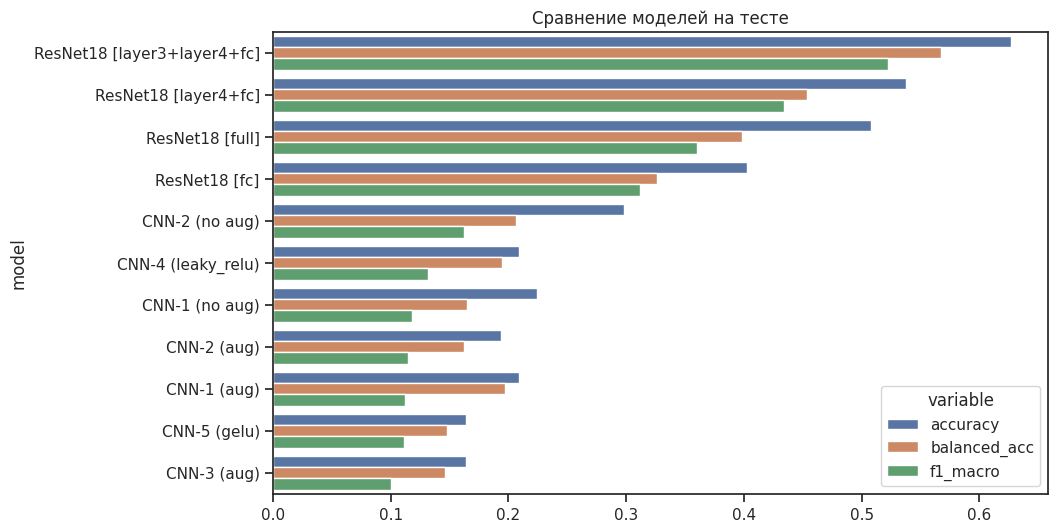

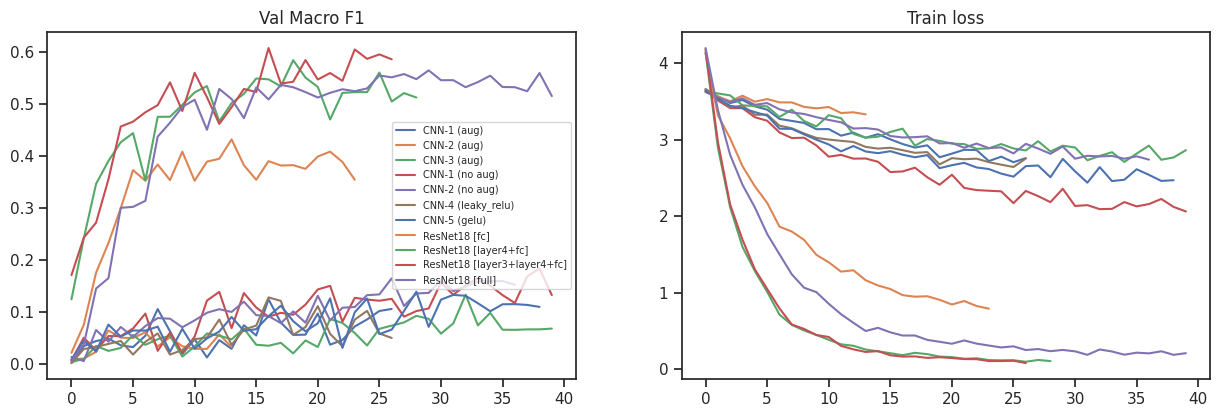

CNN-1: F1 aug=0.112 vs no-aug=0.118 | Acc 0.209 vs 0.224 | BalAcc 0.197 vs 0.164
CNN-2: F1 aug=0.114 vs no-aug=0.162 | Acc 0.194 vs 0.299 | BalAcc 0.162 vs 0.206


In [ ]:
df = pd.DataFrame(all_results)

REQ_COLS = ["model", "trainable_layers", "batch_size", "activation", "optimizer", "lr",
            "best_epoch", "accuracy", "f1_macro"]
EXTRA_COLS = ["family", "augmentation", "class_weights", "balanced_acc", "precision_macro",
              "recall_macro", "best_val_f1", "trainable_params", "epochs_run", "time_s"]
RENAME = {"model": "Model", "trainable_layers": "Trainable layers", "batch_size": "Batch size",
          "activation": "Activation", "optimizer": "Optimizer", "lr": "LR", "best_epoch": "Best epoch",
          "accuracy": "Accuracy", "f1_macro": "Macro F1"}

table = df[REQ_COLS + EXTRA_COLS].sort_values("f1_macro", ascending=False).reset_index(drop=True)
table_req = table[REQ_COLS].rename(columns=RENAME)  # таблица строго по ТЗ (идёт в отчёт)
table.to_csv("results_table_full.csv", index=False)
table_req.to_csv("results_table.csv", index=False)

fmt = {c: "{:.3f}" for c in ["accuracy", "f1_macro", "balanced_acc", "precision_macro", "recall_macro", "best_val_f1"]}
print("=== Таблица по ТЗ (test) ===")
display(table_req.style.format({"Accuracy": "{:.3f}", "Macro F1": "{:.3f}"})
        .background_gradient(subset=["Macro F1"], cmap="Oranges"))
print("=== Расширенная таблица ===")
display(table.style.format(fmt).background_gradient(subset=["f1_macro"], cmap="Oranges"))

fig, ax = plt.subplots(figsize=(10, 6))
tm = table.melt(id_vars="model", value_vars=["accuracy", "balanced_acc", "f1_macro"])
sns.barplot(data=tm, y="model", x="value", hue="variable", ax=ax,
            palette=["#4C72B0", "#DD8452", "#55A868"])
ax.set_title("Сравнение моделей на тесте"); ax.set_xlabel("")
plt.savefig("figures/model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

# сравнение val-кривых (Macro F1) и train loss
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for n, h in train_histories.items():
    ax[0].plot(h["val_f1"], label=n); ax[1].plot(h["train_loss"], label=n)
ax[0].set_title("Val Macro F1"); ax[1].set_title("Train loss")
ax[0].legend(fontsize=7)
plt.savefig("figures/curves_all.png", dpi=150, bbox_inches="tight"); plt.show()

# эффект аугментации (пары; class weights одинаковые)
for base in ["CNN-1", "CNN-2"]:
    a = df[df.model == f"{base} (aug)"].iloc[0]
    b = df[df.model == f"{base} (no aug)"].iloc[0]
    print(f"{base}: F1 aug={a.f1_macro:.3f} vs no-aug={b.f1_macro:.3f} | "
          f"Acc {a.accuracy:.3f} vs {b.accuracy:.3f} | BalAcc {a.balanced_acc:.3f} vs {b.balanced_acc:.3f}")


Лучшая модель по val Macro F1: ResNet18 [layer3+layer4+fc]


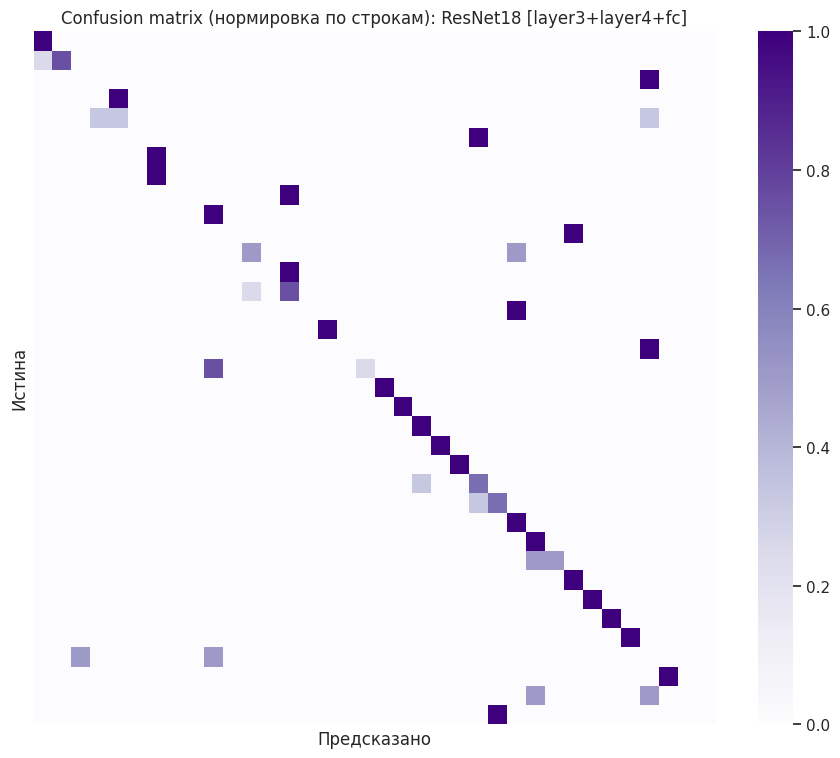

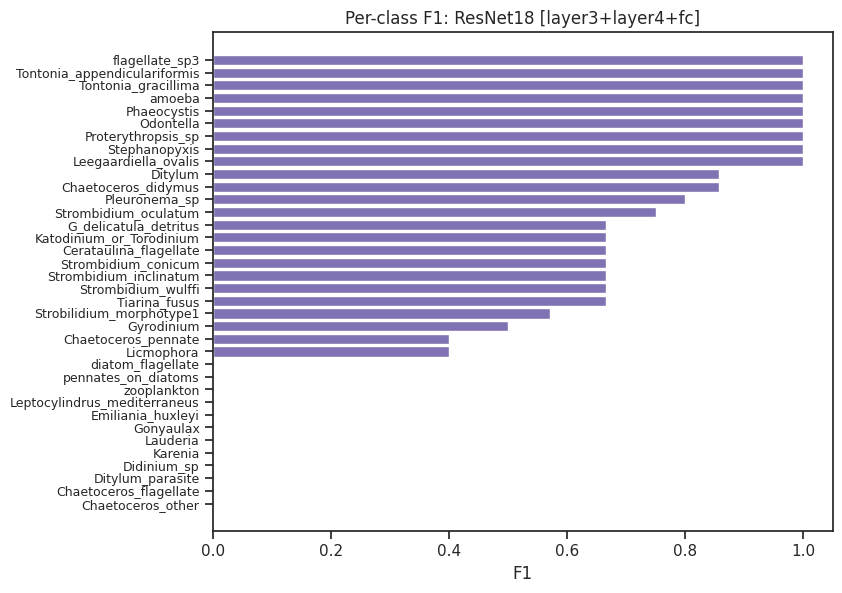

Худшие 10 классов:
 Chaetoceros_other               0.0
Chaetoceros_flagellate          0.0
Ditylum_parasite                0.0
Didinium_sp                     0.0
Karenia                         0.0
Lauderia                        0.0
Gonyaulax                       0.0
Emiliania_huxleyi               0.0
Leptocylindrus_mediterraneus    0.0
zooplankton                     0.0
dtype: float64
Доля классов с F1=0: 0.333


In [ ]:
best_name = df.sort_values("best_val_f1", ascending=False).iloc[0]["model"]  # выбор по val Macro F1, не по test
print("Лучшая модель по val Macro F1:", best_name)
yt, yp = model_preds[best_name]
labs = np.unique(yt)

cm = confusion_matrix(yt, yp, labels=labs)
cmn = cm / cm.sum(1, keepdims=True)
plt.figure(figsize=(11, 9))
small = len(labs) <= 30
sns.heatmap(cmn, cmap="Purples", annot=small, fmt=".1f" if small else "",
            xticklabels=[selected_classes[l][:12] for l in labs] if small else False,
            yticklabels=[selected_classes[l][:12] for l in labs] if small else False)
plt.xlabel("Предсказано"); plt.ylabel("Истина")
plt.title(f"Confusion matrix (нормировка по строкам): {best_name}")
plt.savefig("figures/confusion_matrix_best.png", dpi=150, bbox_inches="tight"); plt.show()

pcf = per_class_f1(yt, yp).sort_values()
pcf.to_csv("per_class_f1_best.csv")
plt.figure(figsize=(8, max(4, 0.18 * len(pcf))))
plt.barh(pcf.index, pcf.values, color="#8172B3")
plt.xlabel("F1"); plt.title(f"Per-class F1: {best_name}")
plt.yticks(fontsize=6 if len(pcf) > 40 else 9)
plt.savefig("figures/per_class_f1_best.png", dpi=150, bbox_inches="tight"); plt.show()
print("Худшие 10 классов:\n", pcf.head(10))
print("Доля классов с F1=0:", (pcf == 0).mean().round(3))

pc_all = pd.DataFrame({n: per_class_f1(*model_preds[n]) for n in model_preds}).round(3)
pc_all.to_csv("per_class_f1_all_models.csv")


## 8. Вывод

**Условия эксперимента.** После отбора классов с 1–20 изображениями осталось 37 классов и 303 изображения. Разбиение при `seed=67`: train — 172, validation — 64, test — 67. В test представлены 36 из 37 классов: класс с одним изображением остаётся только в train. При 67 тестовых изображениях одна ошибка меняет Accuracy примерно на 1,49 п.п.; метрики следует трактовать осторожно.

**1. Влияние аугментаций.** По сохранённым логам CNN-1: Macro F1 0,112 (aug) против 0,118 (no aug), Accuracy 0,209 против 0,224; CNN-2: Macro F1 0,114 против 0,162, Accuracy 0,194 против 0,299. В этом запуске аугментация не улучшила CNN. Это не доказывает, что аугментации в целом вредны: выборка мала, запуск один, а преобразования применяются совместно. Возможные причины — усложнение обучения с нуля и деформация вытянутых изображений при `Resize((224,224))` и `RandomResizedCrop`. Нужны абляции отдельных преобразований и несколько seed.

**2. ResNet18 и глубина дообучения.** Фактические сохранённые логи тестирования: `fc` — Accuracy 0,403, Balanced Accuracy 0,326, Macro F1 0,311; `layer4+fc` — 0,537 / 0,454 / 0,434; `layer3+layer4+fc` — 0,627 / 0,567 / 0,522; `full` — 0,507 / 0,398 / 0,360. В этом запуске лучший тестовый результат получен у `layer3+layer4+fc` (best epoch 17), а не `layer4+fc`. Выбор по validation Macro F1 также указывает на `layer3+layer4+fc` (val F1=0,608). Это исправляет расхождение в прежнем комментарии, где были приведены другие числа.

**3. ResNet18 против собственной CNN.** Среди CNN лучший сохранённый результат — `CNN-2 (no aug)`: Accuracy 0,299, Balanced Accuracy 0,206, Macro F1 0,162. Лучший ResNet18 (`layer3+layer4+fc`) превосходит его по Macro F1 на 0,360 и по Accuracy на 0,328. Результат согласуется с пользой предобученных признаков при малом количестве размеченных изображений.

**4. Функции активации и параметры CNN.** В логах: `CNN-4 (leaky_relu)` Macro F1=0,131; `CNN-5 (gelu)`=0,111; `CNN-1 (aug, relu)`=0,112. Убедительного преимущества альтернативных активаций не видно. `CNN-3` с SGD и lr=1e-2 дал Macro F1=0,101. Все различия нужно трактовать как результаты одного запуска, а не устойчивые закономерности.

**5. Ограничения.** Выборка крайне мала и несбалансирована; тест содержит 67 изображений и 36 оцениваемых классов. Использован один seed (67), поэтому разброс от инициализации и порядка батчей не измерен. Класс с n=1 не оценивается на test. Validation также мала, поэтому выбор эпохи нестабилен. Метрики Precision/Recall и подробные значения таблицы экспериментов не были сохранены в текстовом виде в текущем выводе ноутбука; перед окончательной сдачей рекомендуется перезапустить ячейки 19–20 и сохранить `results_table_full.csv`, `per_class_f1_all_models.csv` и графики.

**Дальнейшая работа.** Повторить эксперименты с несколькими seed или stratified k-fold, оценить доверительные интервалы; провести абляцию аугментаций; сохранить пропорции изображений с padding вместо растяжения; добавить Precision/Recall, per-class F1 и читаемую confusion matrix; сравнивать модели на одном и том же test-наборе.